<a href="https://colab.research.google.com/github/gouthamsankar-clg/BIS_Lab/blob/main/Lab_2/ParticleSarm_EVCharging.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

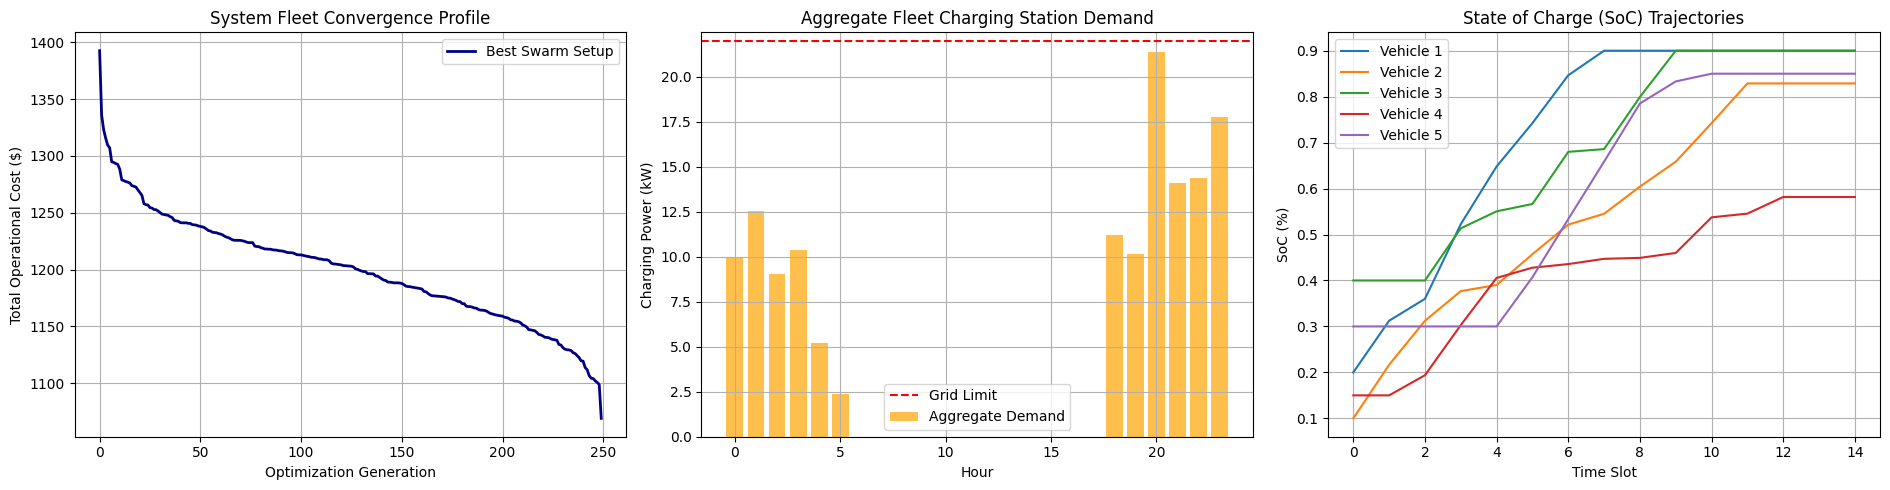

In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

# =====================================================================
# Step 1: Define the Problem
# =====================================================================
HOURS = [18, 19, 20, 21, 22, 23, 0, 1, 2, 3, 4, 5, 6, 7]
PRICES = np.array([9.5, 9.5, 9.5, 9.5, 6.5, 4.5, 4.5, 4.5, 4.5, 4.5, 4.5, 4.5, 6.5, 6.5])
N_SLOTS = len(HOURS)

STATION_MAX_CAPACITY_KW = 22.0

FLEET_VEHICLES = [
    {"id": 1, "soc_init": 0.20, "soc_target": 0.90, "cap": 40.0, "max_kw": 7.4, "arr": 0,  "dep": 13},
    {"id": 2, "soc_init": 0.10, "soc_target": 0.85, "cap": 50.0, "max_kw": 7.4, "arr": 0,  "dep": 11},
    {"id": 3, "soc_init": 0.40, "soc_target": 0.90, "cap": 30.0, "max_kw": 3.7, "arr": 2,  "dep": 13},
    {"id": 4, "soc_init": 0.15, "soc_target": 0.80, "cap": 60.0, "max_kw": 7.4, "arr": 1,  "dep": 12},
    {"id": 5, "soc_init": 0.30, "soc_target": 0.85, "cap": 40.0, "max_kw": 5.5, "arr": 4,  "dep": 13}
]
N_VEHICLES = len(FLEET_VEHICLES)

EFF = 0.92
DT = 1.0
DEG_COEF_CRATE = 5.0
DEG_COEF_HIGH = 15.0
UNMET_PENALTY = 35.0
GRID_OVERLOAD_PENALTY = 50.0

def simulate_fleet(flat_particle):
    matrix = flat_particle.reshape(N_VEHICLES, N_SLOTS)

    fleet_power_trace = np.zeros((N_VEHICLES, N_SLOTS))
    fleet_soc_trace = np.zeros((N_VEHICLES, N_SLOTS + 1))

    total_elec_cost = 0.0
    total_degradation = 0.0
    total_unmet_penalty = 0.0

    for v_idx, v in enumerate(FLEET_VEHICLES):
        soc = v[